# From bat recordings to a deepSTRF dataset

**Internship project · Dataset preparation and integration**

The goal of this project is to make a calcium-imaging dataset usable in
[deepSTRF](https://github.com/urancon/deepSTRF). I connect the recorded responses
to their sound files, bring recording sites into one dataset and check that the
result works with the library's batching, audio processing and linear model.

This notebook follows that process using the original data. The reusable
implementation lives in the Python package under `src/bat_internship/`.

1. [Set up the project](#setup)
2. [Inspect the recordings](#recordings)
3. [Match sounds and merge sites](#merge)
4. [Check values and missing recordings](#checks)
5. [Inspect the actual model inputs](#inputs)
6. [Check the linear model interface](#model)
7. [Train and review a joint linear model](#training)
8. [What the integration achieves](#outcome)

The recordings come from Lawlor et al., *Spatially clustered neurons in the bat
midbrain encode vocalization categories*. The original study provides the
scientific context for the recordings. This project's contribution is the data
preparation and its integration into deepSTRF. [Original study](https://www.nature.com/articles/s41593-025-01932-3)

<a id="setup"></a>
## 1. Set up the project

Install the project from the repository root, then select that Python environment
as the notebook kernel.

```powershell
python -m pip install -r requirements/deepstrf.txt
python -m pip install -e .
```

You need the original `MegadataStruct.mat`, the authors' WAV directory and the
committed audio manifest. The WAV directory must preserve the relative paths in
the manifest. The configuration below is the only place to change input paths.

**Run all** executes the data checks, figures and one forward/backward check.
Model training is opt-in. The default demonstration selects up to five sites,
one per animal, using metadata rather than response strength. Set
`SITE_MODE = "all"` to repeat the demonstration with all 29 sites. A memory check
runs before loading the selected responses.

In [1]:
from pathlib import Path
import sys

# Locate the repository when opened from its root or notebooks directory.
ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "src/bat_internship/bat_audio_dataset.py").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned repository.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import json
import math
import gc
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import Image, display
from bat_internship.bat_data import BatData
from bat_internship.audio_mapping import read_audio_manifest
# Optional notebook progress widgets are not needed by this walkthrough.
import warnings
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="IProgress not found.*")
    from bat_internship.bat_audio_dataset import BatAudioDataset
from bat_internship.site_selection import select_diverse_sites, require_available_memory
from deepSTRF.utils.data import neural_collate

MAT_FILE = ROOT / "data/raw/MegadataStruct.mat"
if not MAT_FILE.is_file():
    MAT_FILE = ROOT / "MegadataStruct.mat"
AUDIO_ROOT = ROOT / "Autorendaten/OneDrive_1_10-5-2026"
MANIFEST_FILE = ROOT / "data/metadata/regular_audio_manifest.csv"

SITE_MODE = "diverse"  # "diverse", "all" or "manual"
MANUAL_SITES = [0, 13]  # Used only in manual mode; indices start at zero.
DT_MS = 32.0
AUDIO_OFFSET_MS = 0.0
N_MELS = 32

for input_path in (MAT_FILE, AUDIO_ROOT, MANIFEST_FILE):
    if not input_path.exists():
        raise FileNotFoundError(f"Missing input: {input_path}. Check the paths above.")
torch.set_num_threads(2)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})
print("Inputs found. Original files are opened for reading.")
print("Python", sys.version.split()[0], "| PyTorch", torch.__version__)

Inputs found. Original files are opened for reading.
Python 3.13.5 | PyTorch 2.14.0+cpu


<a id="recordings"></a>
## 2. Inspect the recordings before loading the responses

A **site** is one recording location. Each site contains several **regions of
interest (ROIs)**, each with a fluorescence trace for repeated presentations of
sounds. Recordings from different sites were collected separately.

The MATLAB/HDF5 reader exposes the response axes as **time × repeat × sound × ROI**.
Reading the metadata first makes the differences in site size and sound coverage
visible without loading the full response arrays.

29 recording sites
5 bats
9,443 ROIs
428 site-specific sound assignments in the manifest


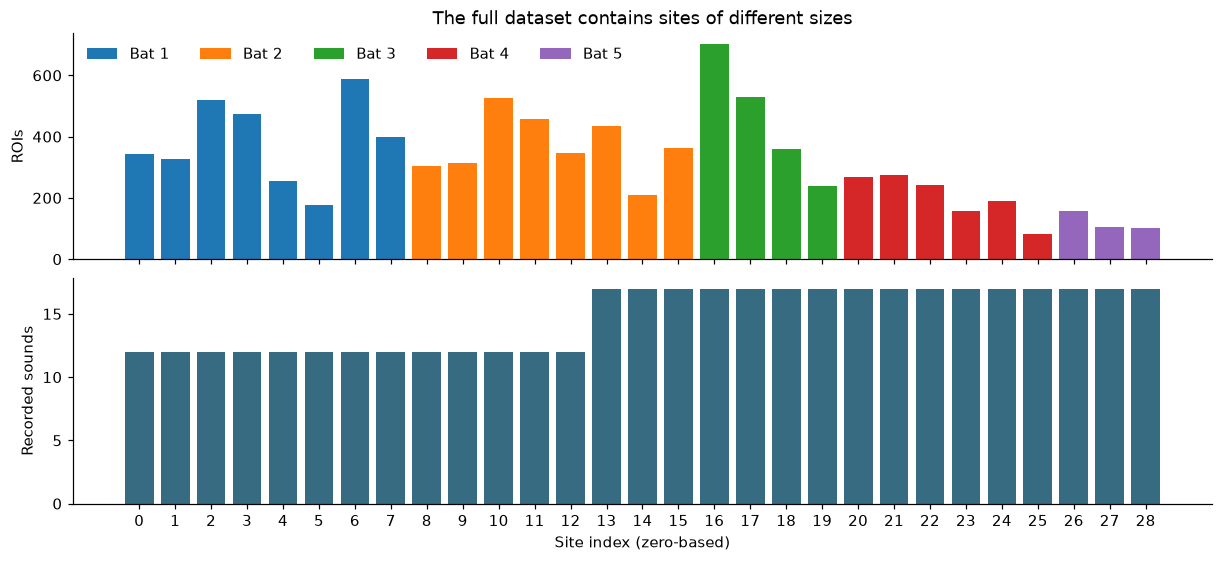

In [2]:
with BatData(MAT_FILE) as source:
    inventory = [source.vocal_metadata(i) for i in range(source.n_sites)]
by_site = {row["site_index"]: row for row in inventory}
manifest = read_audio_manifest(MANIFEST_FILE)

print(f"{len(inventory)} recording sites")
print(f"{len({row['bat_id'] for row in inventory})} bats")
print(f"{sum(row['shape_time_repeat_stimulus_roi'][3] for row in inventory):,} ROIs")
print(f"{len(manifest)} site-specific sound assignments in the manifest")

site_indices = [row["site_index"] for row in inventory]
roi_counts = [row["shape_time_repeat_stimulus_roi"][3] for row in inventory]
sound_counts = [row["shape_time_repeat_stimulus_roi"][2] for row in inventory]
bats = sorted({row["bat_id"] for row in inventory})
colors = {bat: plt.get_cmap("tab10")(i) for i, bat in enumerate(bats)}
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, layout="constrained")
for bat in bats:
    positions = [i for i, row in enumerate(inventory) if row["bat_id"] == bat]
    axes[0].bar([site_indices[i] for i in positions], [roi_counts[i] for i in positions],
                color=colors[bat], label=f"Bat {bat}")
axes[0].set(ylabel="ROIs", title="The full dataset contains sites of different sizes")
axes[0].legend(ncol=len(bats), frameon=False)
axes[1].bar(site_indices, sound_counts, color="#366b82")
axes[1].set(xlabel="Site index (zero-based)", ylabel="Recorded sounds", xticks=site_indices)
plt.show()
plt.close(fig)

<a id="merge"></a>
## 3. Match sound identities and merge the sites

A local sound index is meaningful within its site. To match sounds across sites,
I use the manifest's verified PCM checksum and sample rate. Category labels alone
cannot identify a sound. The loader checks each WAV file against its manifest entry.

A shared sound gets one position on the merged sound axis. ROIs are appended in
site order, with their original site and local ROI index retained. Missing
sound/ROI combinations are represented by NaN sentinels. Repeats stay associated
with their own recording site.

The main implementation is in [bat_audio_dataset.py](../src/bat_internship/bat_audio_dataset.py),
with file checks in [audio_mapping.py](../src/bat_internship/audio_mapping.py).

In [3]:
if SITE_MODE == "all":
    selected_sites = site_indices
elif SITE_MODE == "diverse":
    selection = select_diverse_sites(inventory, max_sites=5, response_budget_mib=64)
    selected_sites = selection["site_indices"]
elif SITE_MODE == "manual":
    selected_sites = list(MANUAL_SITES)
else:
    raise ValueError("SITE_MODE must be all, diverse or manual.")
if (not selected_sites or len(set(selected_sites)) != len(selected_sites)
        or any(type(i) is not int or i not in by_site for i in selected_sites)):
    raise ValueError("Choose distinct valid site indices.")
response_bytes = sum(
    math.prod(by_site[i]["shape_time_repeat_stimulus_roi"]) * 8 for i in selected_sites
)
print("Selected site indices:", selected_sites)
print("Animals:", sorted({by_site[i]["bat_id"] for i in selected_sites}))
print(f"Original response payload: {response_bytes / 1024**2:.1f} MiB")
# Release this notebook's previous dataset when rerunning this section.
globals().pop("dataset", None)
gc.collect()
require_available_memory(response_bytes)

dataset = BatAudioDataset(
    MAT_FILE,
    site_indices=selected_sites,
    audio_root=AUDIO_ROOT,
    mapping_path=MANIFEST_FILE,
    dt_ms=DT_MS,
    audio_offset_ms=AUDIO_OFFSET_MS,
    return_waveform=True,
    n_mels=N_MELS,
)
print(f"Merged: {len(dataset)} unique sounds × {dataset.N_neurons:,} ROIs")

Selected site indices: [5, 14, 19, 25, 28]
Animals: [1, 2, 3, 4, 5]
Original response payload: 50.0 MiB


Merged: 17 unique sounds × 809 ROIs


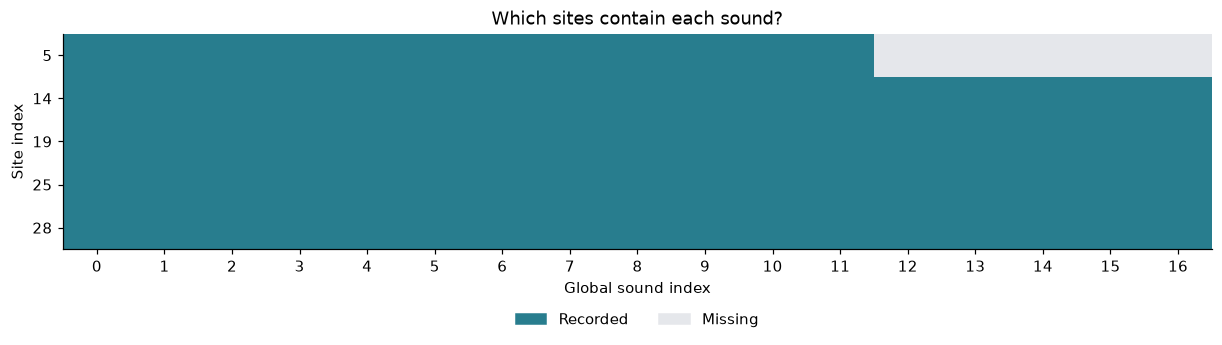

Site 5, local sound 0 → global sound 0
Relative WAV path: Vocalization/boutFMBBn.wav
ROI origin: bat_1_site_6_roi_0


In [4]:
# Every site keeps its own mapping onto the common sound axis.
coverage = np.zeros((len(selected_sites), len(dataset)), dtype=bool)
for row, site in enumerate(selected_sites):
    coverage[row, dataset.local_to_global[site]] = True

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
fig, ax = plt.subplots(figsize=(11, max(3, len(selected_sites) * 0.25)), layout="constrained")
ax.imshow(coverage, aspect="auto", interpolation="nearest",
          cmap=ListedColormap(["#e5e7eb", "#287d8e"]), vmin=0, vmax=1)
ax.set(yticks=range(len(selected_sites)), yticklabels=selected_sites,
       xticks=range(len(dataset)), xlabel="Global sound index", ylabel="Site index",
       title="Which sites contain each sound?")
ax.legend(handles=[Patch(color="#287d8e", label="Recorded"),
                   Patch(color="#e5e7eb", label="Missing")],
          loc="upper center", bbox_to_anchor=(0.5, -0.23), ncol=2, frameon=False)
plt.show()
plt.close(fig)

example_site = selected_sites[0]
example_local_sound = 0
example_global_sound = dataset.local_to_global[example_site][example_local_sound]
example_global_roi = dataset.roi_ranges[0].start
print(f"Site {example_site}, local sound {example_local_sound} → global sound {example_global_sound}")
print("Relative WAV path:", dataset.stim_meta[example_global_sound]["wav_path"])
print("ROI origin:", dataset.nrn_meta[example_global_roi]["cell_id"])

<a id="checks"></a>
## 4. Check that merging preserves the data

For every selected site and sound, the next cell compares the merged responses
with the original HDF5 values. It also checks that missing pairs contain the
expected sentinel. This is an exact comparison of the stored float64 values.

The following batch check covers every merged sound. It verifies both the
available repeats and the NaN padding introduced for sites with fewer repeats.
These checks address data preservation and missingness before model performance
is considered.

In [5]:
verified_values = 0
missing_pairs = 0
with BatData(MAT_FILE) as source:
    for site, bounds in zip(dataset.site_indices, dataset.roi_ranges):
        for local_sound, global_sound in enumerate(dataset.local_to_global[site]):
            original = source.dataset(site, "VocalizationMat")[:, :, local_sound, :]
            for local_roi, response in enumerate(dataset.responses[global_sound][bounds]):
                assert response.dtype == torch.float64
                np.testing.assert_array_equal(response.numpy().T, original[:, :, local_roi])
            verified_values += original.size
            del original
        absent = set(range(len(dataset))) - set(dataset.local_to_global[site])
        for sound in absent:
            for response in dataset.responses[sound][bounds]:
                assert response.shape == (1, 1) and torch.isnan(response).all()
                missing_pairs += 1
assert verified_values * 8 == response_bytes
print(f"PASS — {verified_values:,} original response values preserved exactly")
print(f"PASS — {missing_pairs:,} missing sound/ROI pairs marked explicitly")

PASS — 6,560,130 original response values preserved exactly
PASS — 890 missing sound/ROI pairs marked explicitly


In [6]:
for sound in range(len(dataset)):
    checked_batch = neural_collate([dataset[sound]])
    assert torch.equal(checked_batch["valid_mask"], torch.isfinite(checked_batch["responses"]))
    for site, bounds in zip(dataset.site_indices, dataset.roi_ranges):
        mask = checked_batch["valid_mask"][0, bounds]
        if sound in dataset.local_to_global[site]:
            repeats = by_site[site]["shape_time_repeat_stimulus_roi"][1]
            assert mask[:, :repeats].all()
            assert not mask[:, repeats:].any()
        else:
            assert not mask.any()
    del checked_batch
print(f"PASS — batch masks checked for all {len(dataset)} sounds")

PASS — batch masks checked for all 17 sounds


<a id="inputs"></a>
## 5. Inspect the waveform, model spectrogram and calcium response

The dataset stores aligned waveforms. The native deepSTRF frontend converts them
into 32-band mel spectrograms inside the model. The figure below uses that same
frontend, so its middle panel shows the actual model features.

For this implementation, the frame interval is set to **32 ms** and the WAV onset
to **0 ms**. Each feature bin covers the interval ending at the displayed time.
These remain explicit timing assumptions. The original fluorescence values are
kept in their supplied scale. Their exported F/F₀ versus ΔF/F₀ convention still
needs confirmation.

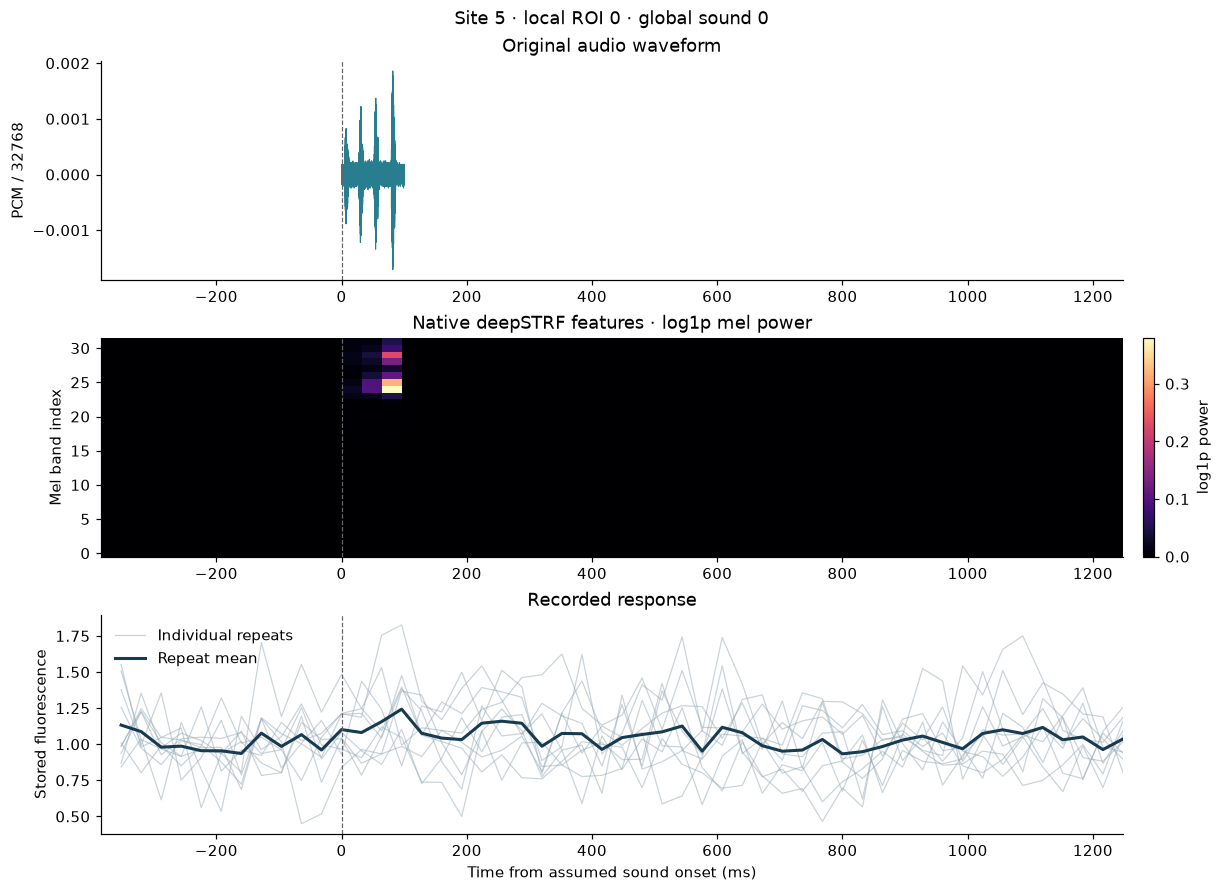

In [7]:
frontend = dataset.make_wav2spec()
with torch.no_grad():
    example_mel = frontend(dataset.stims[example_global_sound].unsqueeze(0))[0, 0].numpy()
assert example_mel.shape == (N_MELS, len(dataset.time_ms))

waveform = dataset.waveforms[example_global_sound]
waveform_time = np.arange(len(waveform)) * 1000 / dataset.audio_fs + AUDIO_OFFSET_MS
trials = dataset.responses[example_global_sound][example_global_roi].numpy()
time_ms = dataset.time_ms
fig, axes = plt.subplots(3, 1, figsize=(11, 8), layout="constrained")
axes[0].plot(waveform_time, waveform, color="#287d8e", lw=0.6)
axes[0].set(ylabel="PCM / 32768", title="Original audio waveform")
mel_image = axes[1].imshow(
    example_mel, origin="lower", aspect="auto", interpolation="nearest",
    extent=[time_ms[0] - DT_MS, time_ms[-1], -0.5, N_MELS - 0.5], cmap="magma",
)
axes[1].set(ylabel="Mel band index", title="Native deepSTRF features · log1p mel power")
fig.colorbar(mel_image, ax=axes[1], label="log1p power", pad=0.02)
for repeat, trace in enumerate(trials):
    axes[2].plot(time_ms, trace, color="#95a8b4", alpha=0.5, lw=0.8,
                 label="Individual repeats" if repeat == 0 else None)
axes[2].plot(time_ms, trials.mean(axis=0), color="#163b51", lw=2, label="Repeat mean")
axes[2].set(ylabel="Stored fluorescence", title="Recorded response",
            xlabel="Time from assumed sound onset (ms)")
axes[2].legend(frameon=False)
for ax in axes:
    ax.axvline(0, color="#666666", ls="--", lw=0.8)
    ax.set_xlim(time_ms[0] - DT_MS, time_ms[-1])
fig.suptitle(f"Site {example_site} · local ROI 0 · global sound {example_global_sound}")
plt.show()
plt.close(fig)

<a id="model"></a>
## 6. Check the linear model interface

The model has one output for each ROI in the merged dataset. The following cell
checks the waveform batch, prediction shape, masked loss and gradients. It makes
no optimizer update. The loss belongs to an untrained model and is only used to
check that the computation is finite.

The library's loss averages observed repeats and excludes missing targets.
I compare it with an explicit per-ROI calculation as an additional check.

In [8]:
from bat_internship.training import build_model
from deepSTRF.metrics import mse_loss

# Include a partially recorded sound if the selected sites contain one.
partial_sounds = np.flatnonzero(~coverage.all(axis=0))
check_sounds = [0, int(partial_sounds[0])] if len(partial_sounds) else [0, 1]
check_sounds = list(dict.fromkeys(check_sounds))
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(42)
    model = build_model("linear", dataset)
    model.eval()
    batch = neural_collate([dataset[i] for i in check_sounds])
    prediction = model(batch["stims"])
    assert prediction.shape == (len(check_sounds), dataset.N_neurons, 1, len(time_ms))
    assert torch.isfinite(prediction).all()
    loss = mse_loss(prediction, batch["responses"])
    target = batch["responses"].nanmean(dim=2, keepdim=True)
    per_roi_error = (prediction.detach() - target).square().nanmean(dim=(0, 2, 3))
    torch.testing.assert_close(loss.detach(), per_roi_error.nanmean())
    loss.backward()
    gradients = [p.grad for p in model.parameters() if p.grad is not None]
    assert gradients and all(torch.isfinite(g).all() for g in gradients)
    assert any(torch.count_nonzero(g) for g in gradients)
    print("Waveform batch:", tuple(batch["stims"].shape))
    print("Response batch:", tuple(batch["responses"].shape))
    print("Predictions:", tuple(prediction.shape))
    print("PASS — prediction shape, masked loss and finite nonzero gradients")
# Release the model and batch before optional training in a separate process.
del model, batch, prediction, target, loss, gradients, per_roi_error

Waveform batch: (2, 1, 326400)
Response batch: (2, 809, 10, 51)
Predictions: (2, 809, 1, 51)
PASS — prediction shape, masked loss and finite nonzero gradients


<a id="training"></a>
## 7. Train and review one joint linear model

Training provides a practical validation of the integration. Sounds are split
by their shared identity, so all sites and repeats of a sound stay in the same
group. Three sounds are reserved for validation and three for a future test.
The remaining sounds are used for training. Test sounds are not evaluated here.

Initialization and the constant per-ROI baseline use only observed training
responses. The same missing-value handling is used for prediction metrics.
Each run records its configuration, site/ROI mapping and sound split.

The default below prepares a three-epoch smoke run. Set `RUN_TRAINING = True`
to launch it, or copy the printed command into a terminal at the repository root.
For a longer run, set `SMOKE = False`. The executable comes from this kernel's
Python environment. The trainer currently expects the standard repository data
paths shown in section 1.

Full protocol details are in [training_pilot.md](../docs/training_pilot.md).

In [9]:
import subprocess
from bat_internship.paths import MAT_PATH as TRAINER_MAT_PATH

RUN_TRAINING = False
SMOKE = True
SEED = 42
SPLIT_SEED = 42
EPOCHS = 100
PATIENCE = 15
LEARNING_RATE = 0.0003
RESULT_ROOT = ROOT / "outputs/linear_dataset_validation"

training_command = [
    sys.executable, "scripts/train_audio_models.py",
    "--sites", *map(str, selected_sites),
    "--linear-init", "train-statistics", "--validation-only",
    "--seed", str(SEED), "--split-seed", str(SPLIT_SEED),
    "--epochs", str(EPOCHS), "--patience", str(PATIENCE),
    "--learning-rate", str(LEARNING_RATE),
    "--output-root", "outputs/linear_dataset_validation",
]
if SMOKE:
    training_command.append("--smoke")
# Use a portable environment-relative executable in the displayed command.
print("From the repository root, with the project environment active:")
print("python " + " ".join(training_command[1:]))
if RUN_TRAINING:
    if (MAT_FILE.resolve() != TRAINER_MAT_PATH.resolve()
            or AUDIO_ROOT.resolve() != (ROOT / "Autorendaten/OneDrive_1_10-5-2026").resolve()
            or MANIFEST_FILE.resolve() != (ROOT / "data/metadata/regular_audio_manifest.csv").resolve()):
        raise ValueError("The trainer uses the standard repository data paths. Match those paths first.")
    # The separate process reloads the selected sites; release the demo dataset.
    del dataset
    gc.collect()
    subprocess.run(training_command, cwd=ROOT, check=True,
                   creationflags=getattr(subprocess, "CREATE_NO_WINDOW", 0))
else:
    print("Training is prepared; no optimizer run was launched.")

From the repository root, with the project environment active:
python scripts/train_audio_models.py --sites 5 14 19 25 28 --linear-init train-statistics --validation-only --seed 42 --split-seed 42 --epochs 100 --patience 15 --learning-rate 0.0003 --output-root outputs/linear_dataset_validation --smoke
Training is prepared; no optimizer run was launched.


### Review a matching completed run

This cell reads only completed runs with the selected sites and protocol. It
works even when no local results exist. MSE is averaged over ROIs with observed
targets. Improvement is measured relative to the training-only constant baseline.

A three-epoch run checks the training path; longer training is needed before
interpreting prediction quality. Results from one site selection do not establish
performance across the full dataset.

In [10]:
expected = {
    "site_indices": selected_sites,
    "smoke": SMOKE, "seed": SEED, "split_seed": SPLIT_SEED,
    "split_strategy": "category-coverage",
    "linear_initialization": "train-statistics",
    "test_evaluation": "disabled", "learning_rate": LEARNING_RATE,
    "epochs": 3 if SMOKE else EPOCHS, "patience": PATIENCE,
}
matching_runs = []
for summary_path in sorted(RESULT_ROOT.glob("*/summary.json")):
    run = summary_path.parent
    config = json.loads((run / "config.json").read_text(encoding="utf-8"))
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
    if (summary.get("status") == "complete" and set(summary.get("models", {})) == {"linear"}
            and all(config.get(key) == value for key, value in expected.items())):
        matching_runs.append(run)
if not matching_runs:
    print("No completed run matches this selection and protocol yet.")
else:
    run = matching_runs[-1]
    metrics = json.loads((run / "linear/metrics.json").read_text(encoding="utf-8"))
    scores = metrics["validation"]
    print("Run:", run.name)
    print("Epochs completed:", metrics["epochs_completed"])
    print("Model MSE:", scores["model"]["mean_mse"])
    print("Constant-baseline MSE:", scores["constant_baseline"]["mean_mse"])
    print("Relative MSE improvement:", scores["relative_mse_improvement"])
    print("ROIs evaluated:", scores["model"]["rois_evaluated"])
    for site, site_scores in scores["sites"].items():
        print("Site", site, "| relative MSE improvement:", site_scores.get("relative_mse_improvement"),
              "| status:", site_scores.get("status", "evaluated"))
    for filename in ("learning_curve.png", "predictions.png"):
        display(Image(filename=str(run / "linear" / filename)))

No completed run matches this selection and protocol yet.


<a id="outcome"></a>
## 8. What the integration achieves

The reusable dataset connects each sound to its recorded responses and preserves
the origin of every ROI. Shared sounds are represented once, while missing
recordings remain explicit. Native deepSTRF processing turns aligned waveforms
into model features, and the linear interface check exercises the forward and
backward paths.

The printed checks and figures above describe the selected demonstration sites.
The same interface accepts the full set through `site_indices` or the trainer's
`--all-sites` option. Loading all sites and training all outputs require more RAM.

The remaining scientific questions concern the exact timing and fluorescence
conventions, and how prediction quality varies across recordings. Those should
be documented alongside the implementation checks in the internship report.

For further inspection:

- [Dataset implementation](../src/bat_internship/bat_audio_dataset.py)
- [Audio identity and file checks](../src/bat_internship/audio_mapping.py)
- [Joint linear trainer](../scripts/train_audio_models.py)
- [Dataset tests](../tests/test_bat_audio_multisite.py)
- [Training and missing-value tests](../tests/test_training.py)
- [Full-dataset validation script](../scripts/validate_all_audio_dataset.py)

Run the automated checks from the repository root with
`python -m unittest discover -s tests` after installing the package.